# 03. Evaluasi dan Grad-CAM

Notebook ini memuat bobot terbaik kedua model, mengevaluasinya pada test set, lalu membuat visualisasi Grad-CAM.

**Metode evaluasi**
- Threshold dipilih dari **val set** (F1 tertinggi pada rentang 0,10 sampai 0,90). Test set tidak dipakai untuk memilih threshold.
- Metrik dihitung pada test set dengan rasio kelas asli.
- Grad-CAM memakai layer konvolusi terakhir: `conv5_block3_out` (ResNet50) dan `top_conv` (EfficientNet-B0).

**Prasyarat:** notebook 01 dan 02 sudah dijalankan.

**Keluaran**
- `results/metrics_comparison.csv`: metrik kedua model.
- `results/predictions_<Model>.csv`: probabilitas prediksi per citra test.
- `images/<Model>_evaluation.png`, `images/roc_comparison.png`, `images/gradcam/*.png`.

In [1]:
import sys
from pathlib import Path

# Notebook dijalankan dari folder notebooks/. Akar repositori ada satu tingkat di atasnya.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from src import config, data, evaluation, gradcam, preprocessing, training, visualization
from src.models import MODEL_SPECS

warnings.filterwarnings("ignore")

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Muat data dan model

In [2]:
X_val_u8, y_val = preprocessing.load_cache("val")
X_test_u8, y_test = preprocessing.load_cache("test")

_, _, df_test = data.load_splits()
assert len(df_test) == len(y_test), "Daftar split dan cache tidak sama panjang. Jalankan ulang notebook 01."

models = {}
for name in config.MODEL_NAMES:
    path = config.MODELS_DIR / f"{name}_best.keras"
    if not path.exists():
        raise FileNotFoundError(f"{path} tidak ada. Jalankan notebook 02 terlebih dahulu.")
    models[name] = tf.keras.models.load_model(path)
    print("Model dimuat:", path.name)

Model dimuat: ResNet50_best.keras
Model dimuat: EfficientNetB0_best.keras


## 2. Prediksi

Setiap model menerima citra dengan normalisasi miliknya sendiri.

In [3]:
X_test_model, probs_val, probs_test = {}, {}, {}
for name, model in models.items():
    preprocess = MODEL_SPECS[name].preprocess_input
    X_val_m = training.prepare_inputs(X_val_u8, preprocess)
    X_test_model[name] = training.prepare_inputs(X_test_u8, preprocess)
    probs_val[name] = model.predict(X_val_m, verbose=0).flatten()
    probs_test[name] = model.predict(X_test_model[name], verbose=0).flatten()
    del X_val_m
print("Prediksi selesai.")

Prediksi selesai.


## 3. Evaluasi ResNet50

  Threshold optimal (dari val set, F1=0.9388): 0.87
  HASIL EVALUASI ResNet50  (threshold = 0.87)
  Accuracy                : 0.9784  (97.84 %)
  Precision               : 0.9070
  Sensitivity (Recall)    : 0.8667
  Specificity             : 0.9904
  F1-Score                : 0.8864
  AUC-ROC                 : 0.9878
--------------------------------------------------------------
  TP=39  TN=413  FP=4  FN=6


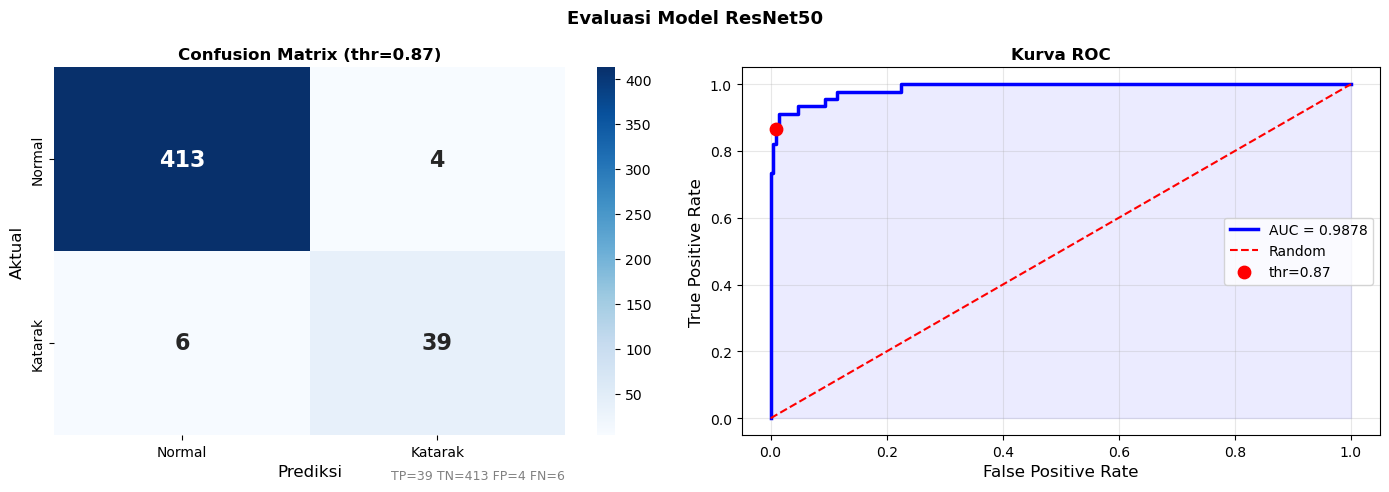


Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       417
     Katarak       0.91      0.87      0.89        45

    accuracy                           0.98       462
   macro avg       0.95      0.93      0.94       462
weighted avg       0.98      0.98      0.98       462



In [4]:
results = {}
results["ResNet50"] = evaluation.evaluate(
    "ResNet50", y_val, probs_val["ResNet50"], y_test, probs_test["ResNet50"],
    plot_path=config.IMAGES_DIR / "ResNet50_evaluation.png")

## 4. Evaluasi EfficientNet-B0

  Threshold optimal (dari val set, F1=0.9574): 0.79
  HASIL EVALUASI EfficientNetB0  (threshold = 0.79)
  Accuracy                : 0.9784  (97.84 %)
  Precision               : 0.9070
  Sensitivity (Recall)    : 0.8667
  Specificity             : 0.9904
  F1-Score                : 0.8864
  AUC-ROC                 : 0.9894
--------------------------------------------------------------
  TP=39  TN=413  FP=4  FN=6


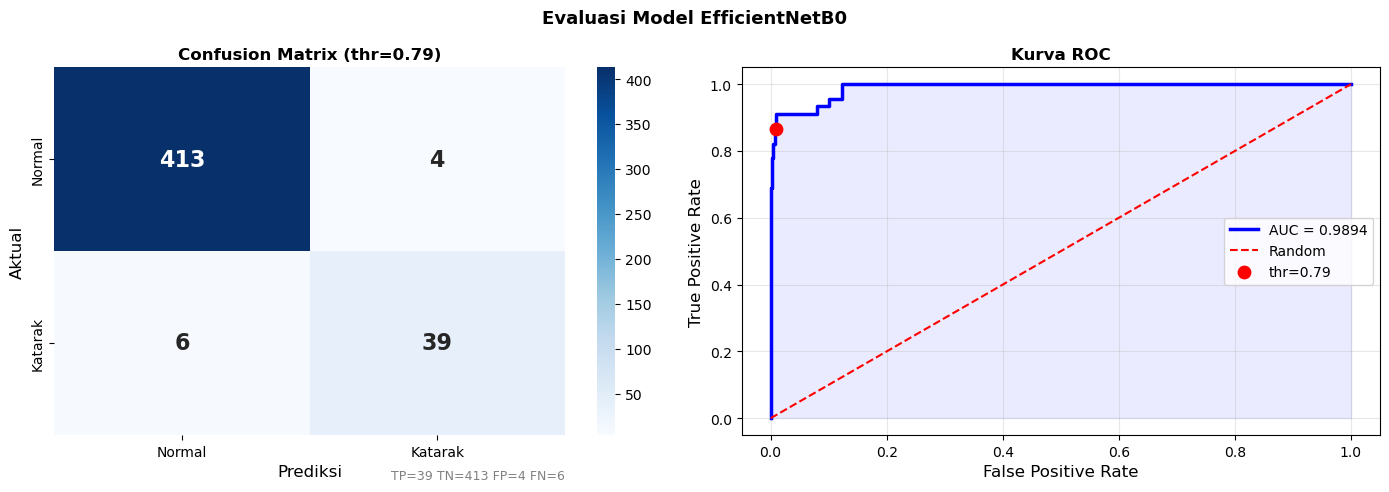


Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       417
     Katarak       0.91      0.87      0.89        45

    accuracy                           0.98       462
   macro avg       0.95      0.93      0.94       462
weighted avg       0.98      0.98      0.98       462



In [5]:
results["EfficientNetB0"] = evaluation.evaluate(
    "EfficientNetB0", y_val, probs_val["EfficientNetB0"], y_test, probs_test["EfficientNetB0"],
    plot_path=config.IMAGES_DIR / "EfficientNetB0_evaluation.png")

## 5. Perbandingan kedua model

Test set memuat 45 citra katarak. Satu citra mengubah recall sekitar 2,2 poin persentase. Baca selisih kecil dengan hati-hati.

In [6]:
table = evaluation.save_results(results, df_test)
table

,model,threshold,accuracy,precision,recall,specificity,f1_score,auc_roc,tp,tn,fp,fn
0,ResNet50,0.87,0.9784,0.907,0.8667,0.9904,0.8864,0.9878,39,413,4,6
1,EfficientNetB0,0.79,0.9784,0.907,0.8667,0.9904,0.8864,0.9894,39,413,4,6


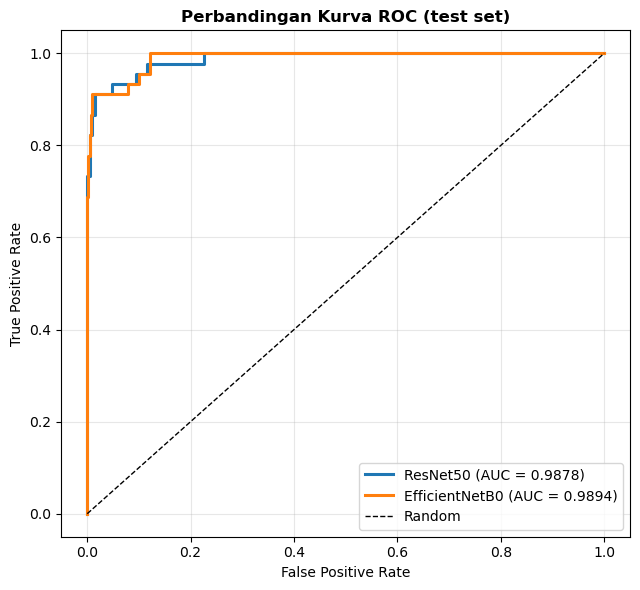

In [7]:
visualization.plot_roc_comparison(results, y_test, save_path=config.IMAGES_DIR / "roc_comparison.png")

## 6. Grad-CAM

Grad-CAM menampilkan area citra yang paling memengaruhi skor kelas Katarak. Tiga kelompok ditampilkan: True Positive (maksimal 4 citra), True Negative (maksimal 4), dan False Negative (maksimal 2).

Heatmap berasal dari feature map 7 x 7, lalu diperbesar ke 224 x 224. Karena itu heatmap menunjukkan wilayah kasar, bukan batas lesi.

### ResNet50

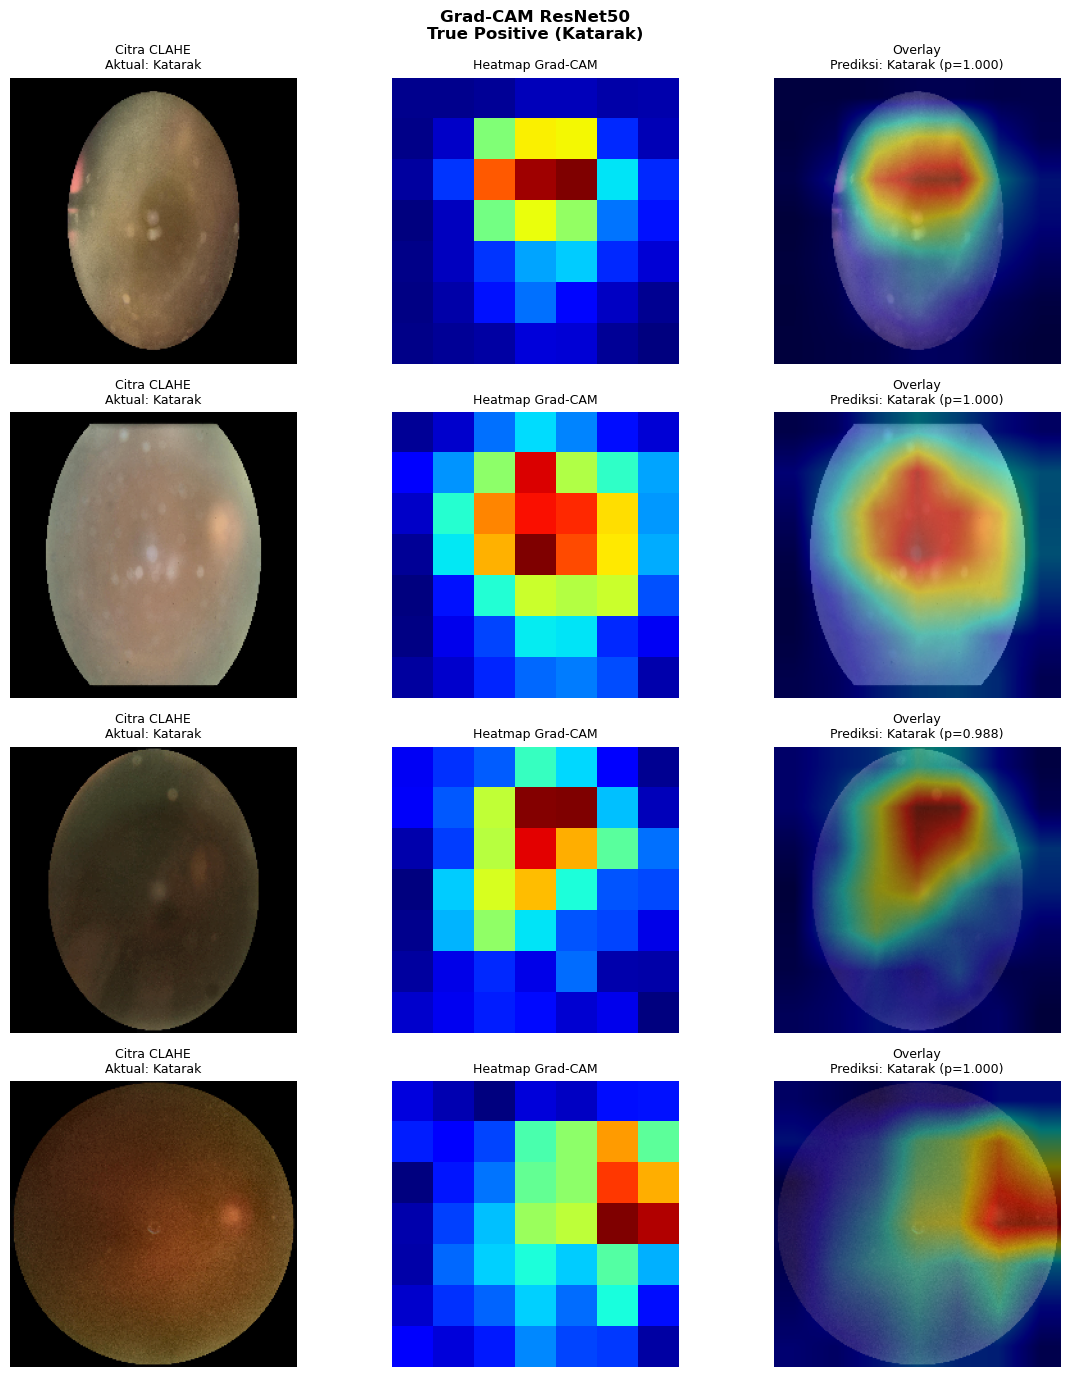

Grad-CAM disimpan: <ROOT>\images\gradcam\ResNet50_true_positive.png


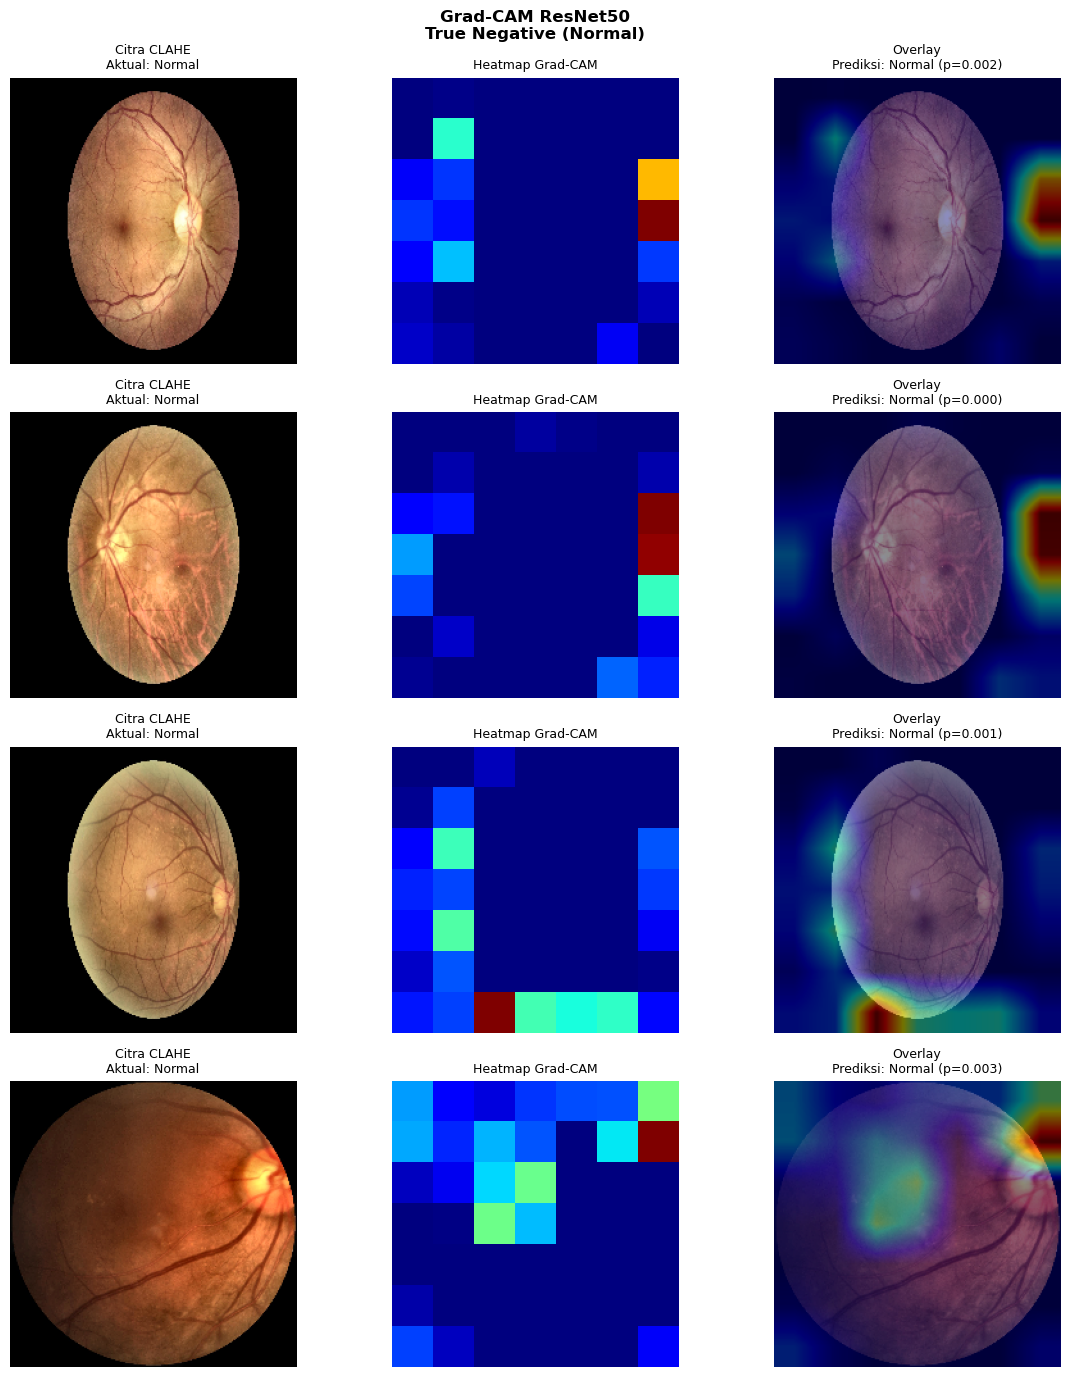

Grad-CAM disimpan: <ROOT>\images\gradcam\ResNet50_true_negative.png


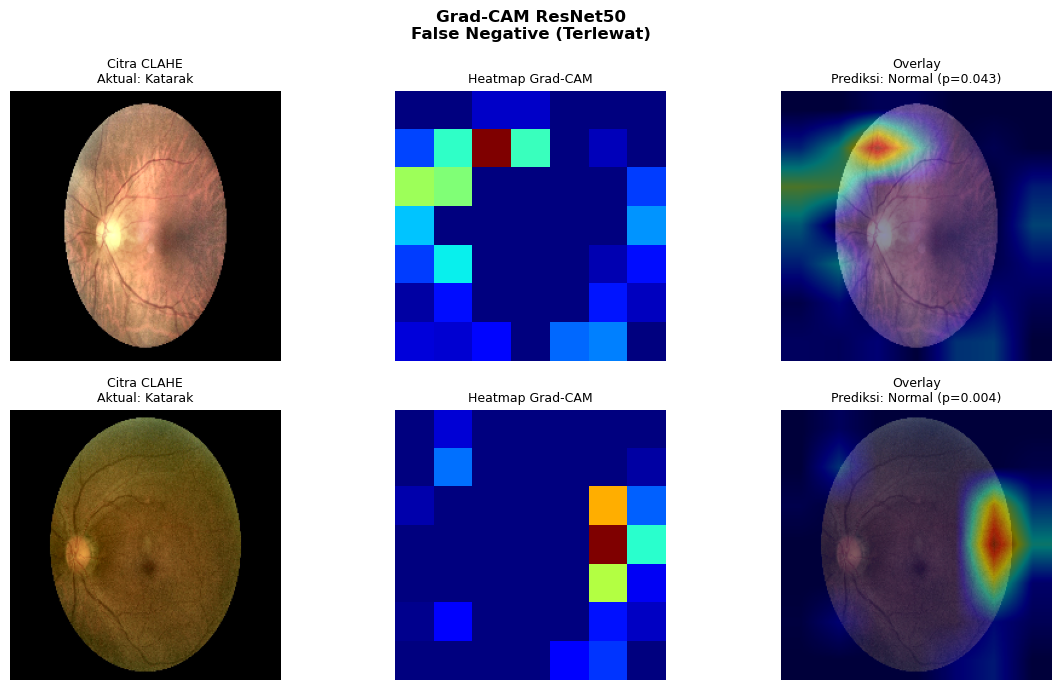

Grad-CAM disimpan: <ROOT>\images\gradcam\ResNet50_false_negative.png


In [8]:
visualize = lambda name: gradcam.visualize_gradcam(
    models[name], X_test_model[name], X_test_u8, y_test, results[name],
    MODEL_SPECS[name].last_conv_layer, name, n_each=4)

visualize("ResNet50")

### EfficientNet-B0

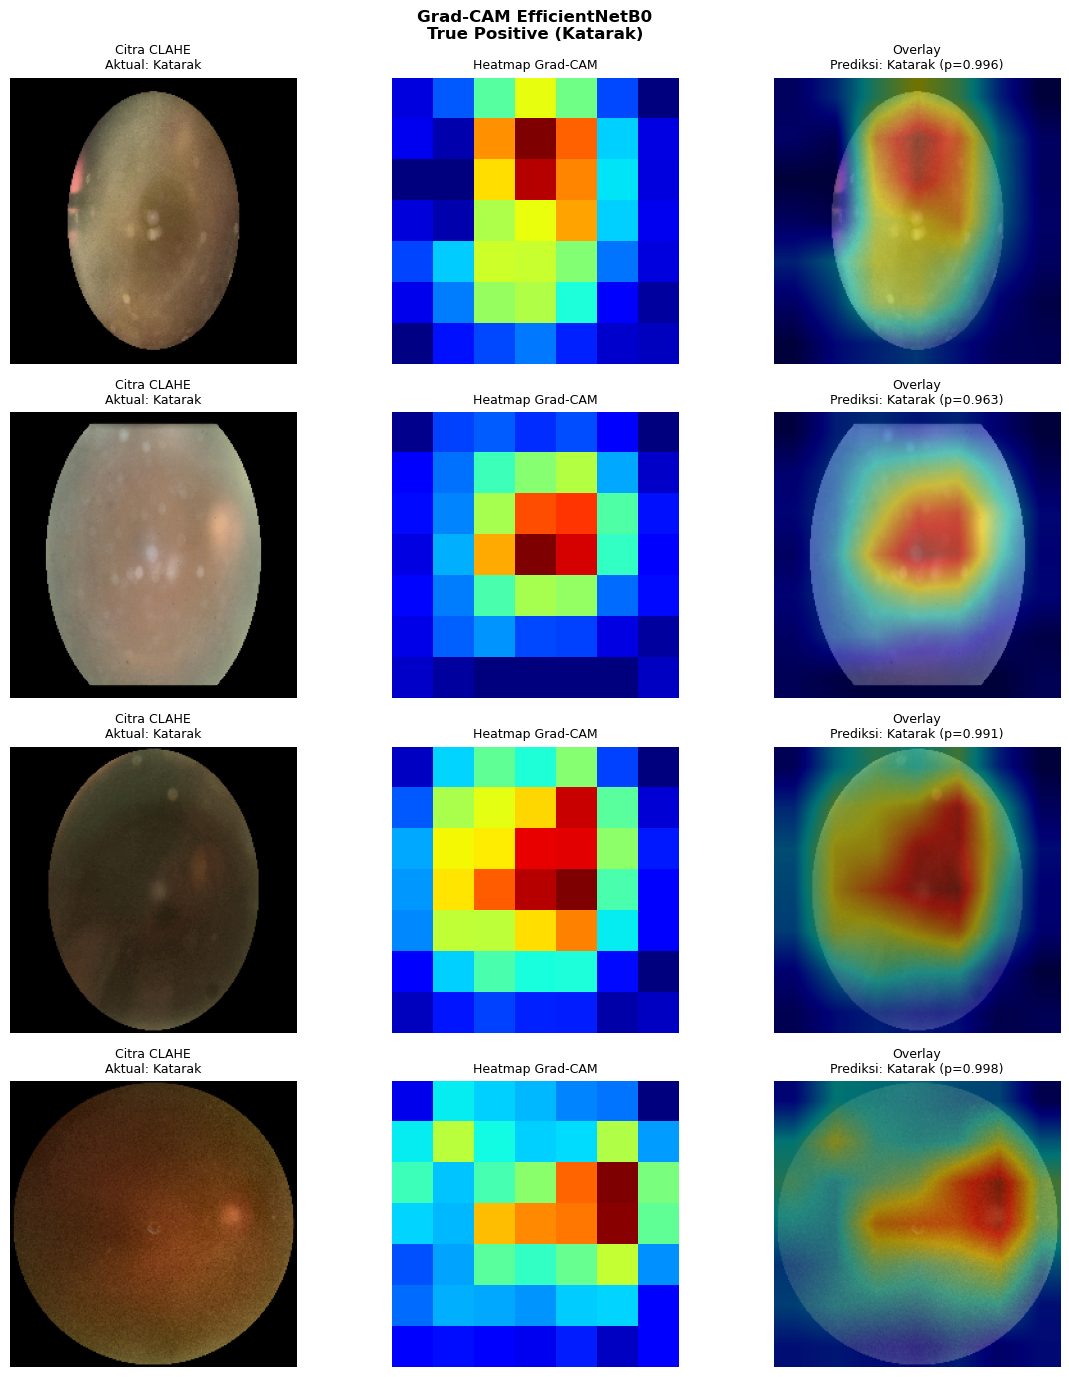

Grad-CAM disimpan: <ROOT>\images\gradcam\EfficientNetB0_true_positive.png


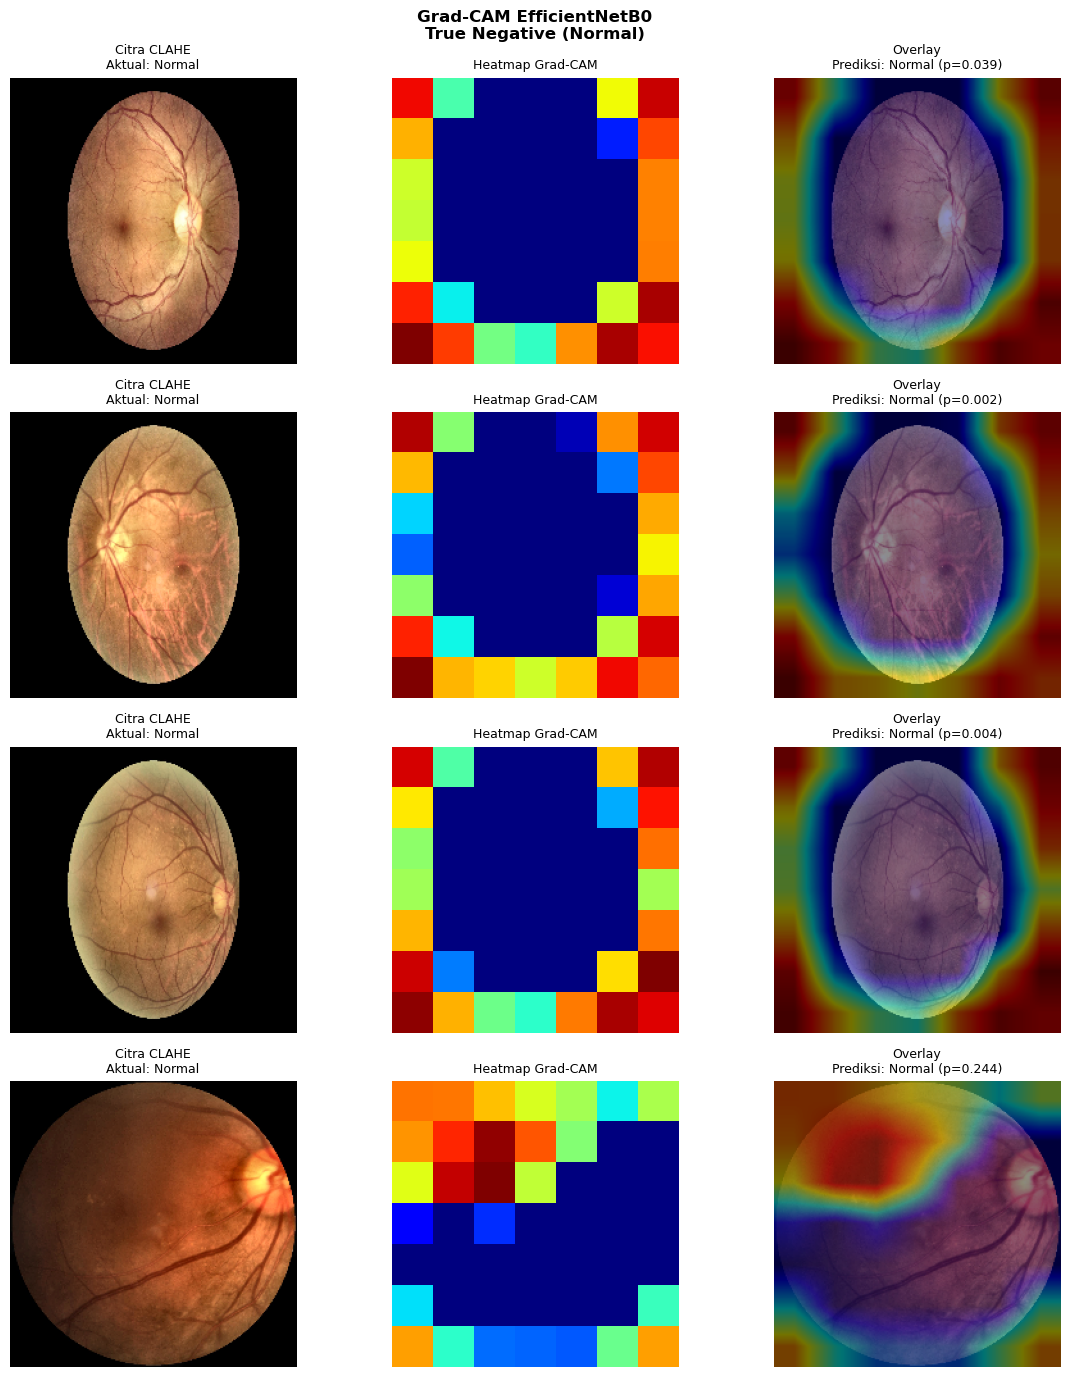

Grad-CAM disimpan: <ROOT>\images\gradcam\EfficientNetB0_true_negative.png


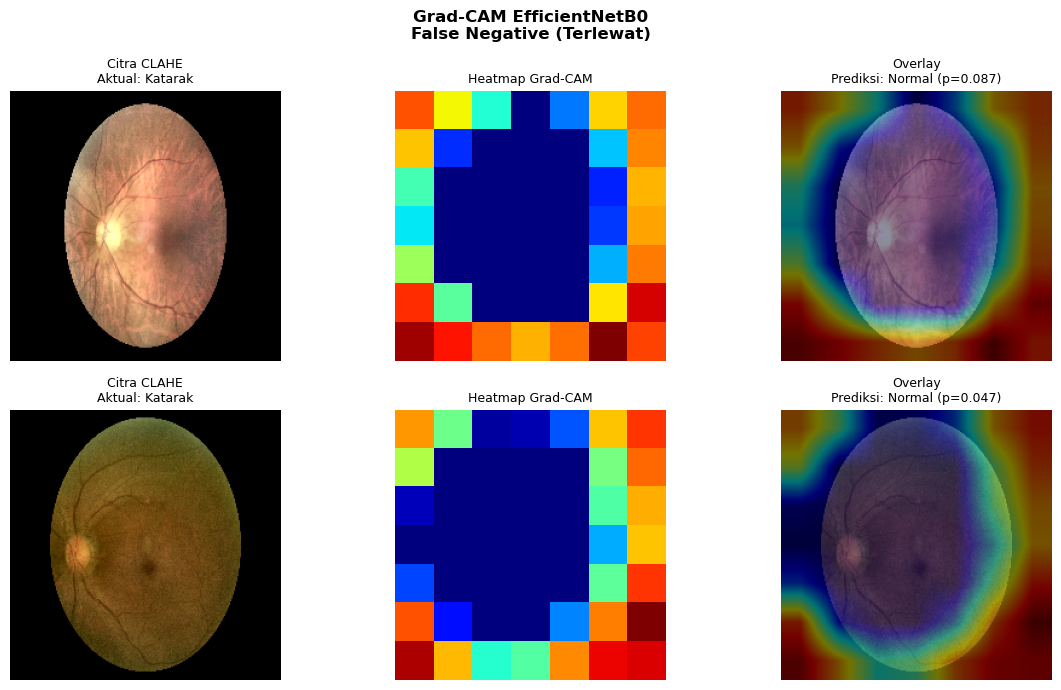

Grad-CAM disimpan: <ROOT>\images\gradcam\EfficientNetB0_false_negative.png


In [9]:
visualize("EfficientNetB0")